# The MoE kernel on H200

The challenge times one routed-experts layer (8 of 256 experts per token, 32 owned per GPU, NVFP4 weights) at six
token counts, and scores the geometric mean of SGLang's time over ours:

$$
S = \exp\!\Big(\frac{1}{6}\sum_{l=1}^{6} \ln \frac{T^{\text{SGLang}}_l}{T_l}\Big).
$$

Each load counts equally, so a 1% gain on any one load moves the score by about 0.17%.

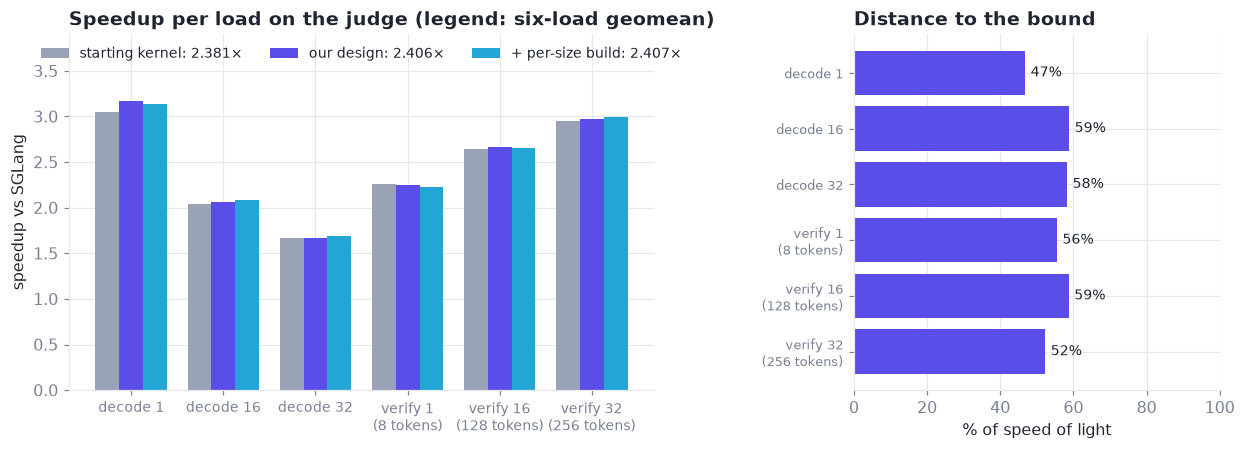

{'starting kernel': 2.381, 'our design': 2.4059, '+ per-size build': 2.4074}


In [1]:
import sys; sys.path[:0] = ['..', '.']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
NAMES = ["decode 1", "decode 16", "decode 32", "verify 1\n(8 tokens)", "verify 16\n(128 tokens)", "verify 32\n(256 tokens)"]
j = pd.read_csv(DATA / "moe_judge.csv"); j["speedup"] = j.sglang_us / j.ours_us
runs, loads = list(dict.fromkeys(j.run)), list(dict.fromkeys(j.load))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.42})
x, wd = np.arange(len(loads)), 0.26
for k, (run, cc) in enumerate(zip(runs, (C["ref"], C["ours"], C["cyan"]))):
    s = j[j.run == run].set_index("load").loc[loads, "speedup"]
    axes[0].bar(x + (k - 1) * wd, s, wd, color=cc, label=f"{run}: {np.exp(np.log(s).mean()):.3f}×")
axes[0].set_xticks(x, NAMES, fontsize=9); axes[0].set_ylabel("speedup vs SGLang"); axes[0].legend(loc="upper center", ncol=3, fontsize=9)
axes[0].set_ylim(0, 3.9); axes[0].set_title("Speedup per load on the judge (legend: six-load geomean)")
last = j[j.run == runs[-1]].set_index("load").loc[loads]
axes[1].barh(range(6)[::-1], last.sol_us / last.ours_us * 100, color=C["ours"])
axes[1].set_yticks(range(6)[::-1], NAMES, fontsize=8.5); axes[1].set_xlim(0, 100)
axes[1].set_xlabel("% of speed of light"); axes[1].set_title("Distance to the bound")
for i, v in enumerate((last.sol_us / last.ours_us * 100).values[::-1]): axes[1].text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=9)
save(fig, "moe_judge_speedups"); plt.show()
print(j.groupby("run", sort=False).speedup.apply(lambda s: round(float(np.exp(np.log(s).mean())), 4)).to_dict())

## Pieces that only work together

Two changes were tested alone and together at 12 seeds × 2 repeats: a grouped HFMA2 dequant for the one-token build,
and a different decoder graph (§01). Alone they gave little. Together they gave **+3.3%** on the one-token load: an
interaction no single-change search would find, which is why the measured search recombines pieces on purpose.

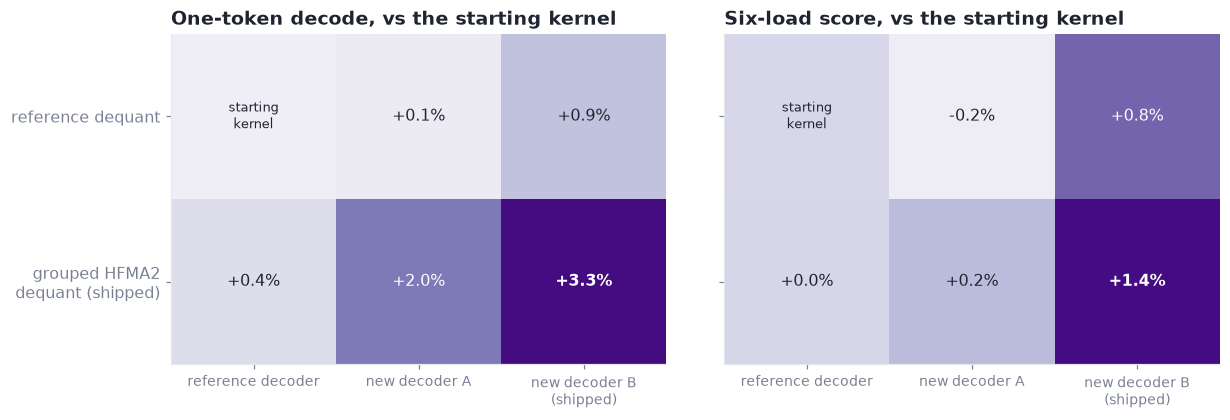

In [2]:
ia = pd.read_csv(DATA / "moe_interaction.csv")
DEC = {"parent": "reference decoder", "1683507725:1": "new decoder A", "1246039045:0": "new decoder B\n(shipped)"}
ARITH = {"dense": "reference dequant", "hfma2_group_d1": "grouped HFMA2\ndequant (shipped)"}
ia["dec"], ia["arith"] = ia.decoder.map(DEC), ia.compute.map(ARITH)
ref = {c: 1.0 for c in ia.columns if c not in ("compute", "decoder", "dec", "arith")}
ia = pd.concat([pd.DataFrame([{**ref, "dec": DEC["parent"], "arith": ARITH["dense"]}]), ia], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, col, title in ((axes[0], "d1", "One-token decode"), (axes[1], "six_load", "Six-load score")):
    pv = ia.pivot_table(index="arith", columns="dec", values=col, aggfunc="first").loc[list(ARITH.values()), list(DEC.values())]
    g = (pv.values - 1) * 100
    ax.imshow(g, cmap="Purples", vmin=-0.5, vmax=g.max() * 1.05)
    ax.set_xticks(range(3), pv.columns, fontsize=9); ax.set_yticks(range(2), pv.index); ax.grid(False)
    for (a, b), v in np.ndenumerate(g):
        txt = "starting\nkernel" if (a, b) == (0, 0) else f"{v:+.1f}%"
        ax.text(b, a, txt, ha="center", va="center", fontsize=10.5 if (a, b) != (0, 0) else 8.5,
                color="white" if v > 0.55 * g.max() else INK, fontweight="bold" if (a, b) == (1, 2) else None)
    ax.set_title(f"{title}, vs the starting kernel")
save(fig, "moe_interaction"); plt.show()

## The landscape around the design

A sweep of 514 designs around the shipped design (new decoders, and compute × activation for the one-token build)
says it sits near a local optimum: it ranks second of 514 on the six-load screen, and first of the 31 designs re-timed
at 12 × 2, tied within noise with the next two (1.0147 vs 1.0146 and 1.0144 over the starting kernel) [M].

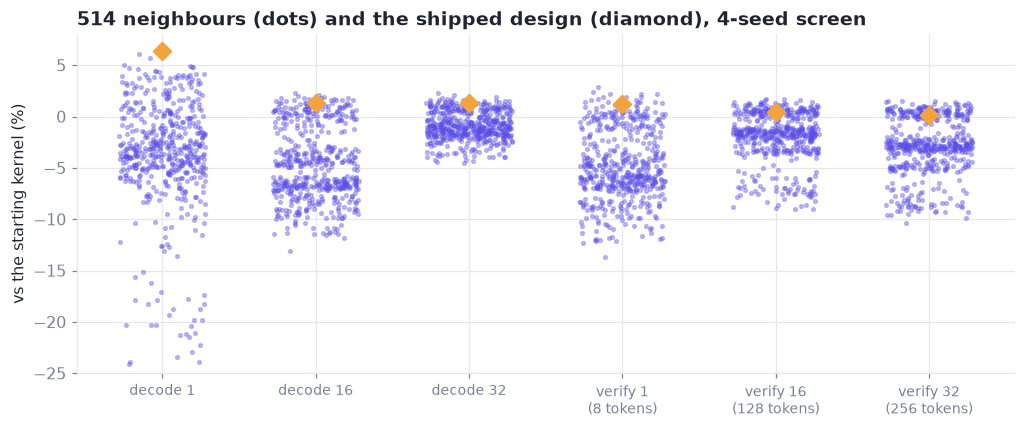

In [3]:
sw = pd.read_csv(DATA / "moe_sweep.csv"); scr = sw[sw.grade == "screen_4x1"]
ctl = scr[scr.group == "control"].iloc[0]
L = ["d1", "d16", "d32", "v1", "v16", "v32"]
fig, ax = plt.subplots(figsize=(11, 4))
for i, l in enumerate(L):
    v = (scr[scr.group != "control"][l] - 1) * 100
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.28, 0.28, len(v)), v, s=6, alpha=0.35, color=C["ours"])
    ax.scatter([i], [(ctl[l] - 1) * 100], marker="D", s=70, color=C["accent"], zorder=5)
ax.set_xticks(range(6), NAMES, fontsize=9)
ax.set_ylabel("vs the starting kernel (%)"); ax.set_ylim(-25, 8)
ax.set_title("514 neighbours (dots) and the shipped design (diamond), 4-seed screen")
save(fig, "moe_landscape"); plt.show()